# 07 · Topological features (persistent homology)

**Idea.** The *shapes* in an image (field boundaries, tree clusters, road lines, building blocks) should
change much less between EuroSAT (Level-1C, haze) and Kaggle (Level-2A) than the band values do. Persistent
homology describes an image by its shapes only: how many separate regions and holes appear and how
long they persist when the image is "flooded" from dark to bright (or bright to dark).

**How** (`src/topology.py`, library `gudhi`):

| Step | Details |
|---|---|
| Height maps | NIR (B08), visible brightness (mean B02–B04), NDVI, edge strength of the brightness |
| Normalisation | every map is **rank-normalised per image** (pixel value → its rank in [0, 1]) |
| Filtrations | sublevel and superlevel per map (edges: superlevel only) → 7 filtrations |
| Homology | dimension 0 (connected regions) and 1 (holes) → 14 persistence diagrams per image |
| Summary per diagram | counts above 3 persistence levels, total/max persistence, entropy, mean birth/midpoint, Betti curve at 8 levels → 16 values, **224 features** |
| Classifier | gradient boosting (`HistGradientBoostingClassifier`) |

**Why rank normalisation.** For a single band, any increasing change of the values (haze removal,
histogram matching, contrast changes) keeps the order of the pixels, so the topology of the
rank-normalised band is **exactly the same** on both domains. NDVI and the visible mean mix bands, so for
them this holds only approximately.

**Comparisons**

- **Baseline:** the same classifier on simple spectral statistics (per band: mean, std, 10/50/90th percentile).
- **Domain shift:** how well a classifier can tell EuroSAT from Kaggle images using each feature set
  (ROC AUC; 0.5 = indistinguishable). Lower = features are more alike in both domains.
- **Kaggle:** agreement with the best model so far (`E06c` + AdaBN, 71.50%), especially on images where E06c is confident.

Literature: Sharma (2025, arXiv:2507.10381) reports 92.4% on EuroSAT with TDA features alone and 99.3%
combined with a ResNet-18 (giotto-tda; not usable here because it has no Python 3.14 support).

Runtime: about 5 minutes (features for 31,000 images on all CPU cores, then cached in `data/cache/`).

## 1 · Setup and data

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CACHE_DIR, CLASSES, PROJECT_ROOT, band_index, load_split, load_test, load_train
from src.experiment import find_run, load_correction, plot_confusion_matrix
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style
from src.preprocessing import land_mask
from src.topology import channels, diagram, feature_names, spectral_features, topological_features
from src.training import load_run, predict_views, to_device_images
from src.utils import get_device

apply_style()
SEED = 0
REFERENCE_RUN = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN, 71.50%

X_all, _ = load_train()
X_all = np.asarray(X_all)
X_kaggle, test_ids = load_test()
X_kg = np.asarray(X_kaggle)
split = load_split()
part = split["split"].values
y_all = split["label_id"].values
print(f"EuroSAT {len(X_all):,} (train {np.sum(part == 'train'):,}, val {np.sum(part == 'val'):,}, "
      f"internal test {np.sum(part == 'test'):,})   Kaggle {len(X_kg):,}")

EuroSAT 27,000 (train 18,900, val 4,050, internal test 4,050)   Kaggle 4,232


## 2 · What the features see

One EuroSAT image per class and Kaggle images predicted as the same class: rank-normalised NIR
and its persistence diagram (sublevel filtration). Each point is a region (H0) or hole (H1): born at
one rank level, merged or filled at a later one. Points far from the diagonal are large, clear structures.

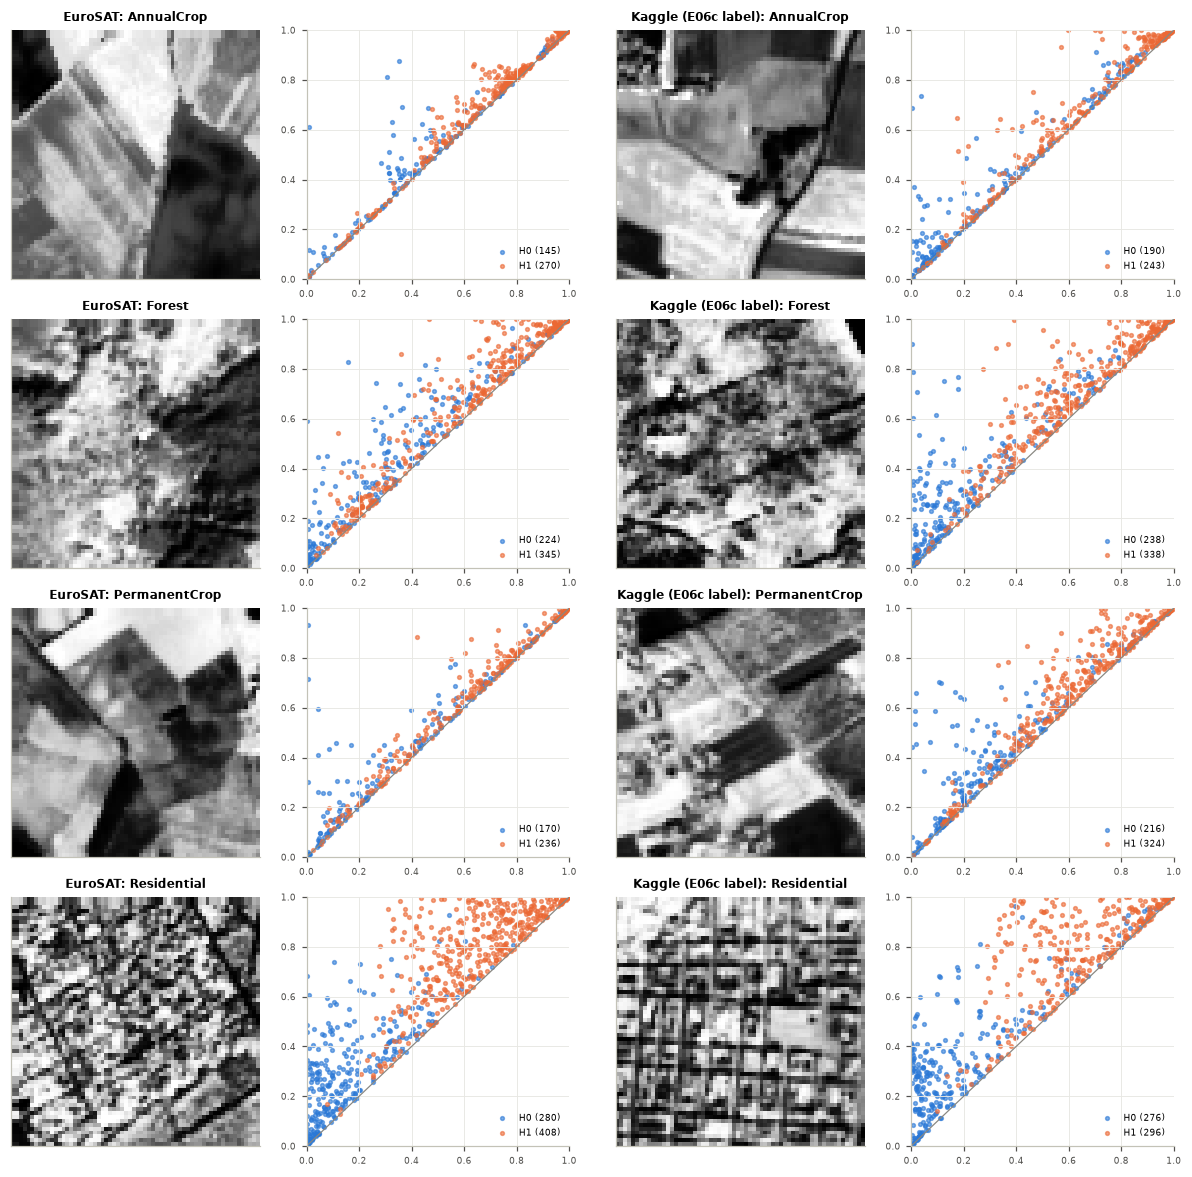

In [2]:
rng = np.random.default_rng(SEED)
ref = pd.read_csv(find_run(REFERENCE_RUN) / "submission.csv")
show = ["AnnualCrop", "Forest", "PermanentCrop", "Residential"]
fig, axes = plt.subplots(len(show), 4, figsize=(11, 2.7 * len(show)))
for r, cls in enumerate(show):
    i_eu = rng.choice(np.flatnonzero(y_all == CLASSES.index(cls)))
    i_kg = rng.choice(np.flatnonzero(ref["label"].values == cls))
    for c, (img, src) in enumerate([(X_all[i_eu], "EuroSAT"), (X_kg[i_kg], "Kaggle (E06c label)")]):
        nir = channels(img)["nir"]
        ax_img, ax_dgm = axes[r, 2 * c], axes[r, 2 * c + 1]
        ax_img.imshow(nir, cmap="gray")
        ax_img.set_xticks([]); ax_img.set_yticks([]); ax_img.grid(False)
        ax_img.set_title(f"{src}: {cls}", fontsize=8)
        for dim, color in [(0, TRAIN_COLOR), (1, TEST_COLOR)]:
            d = diagram(nir, dim)
            ax_dgm.scatter(d[:, 0], d[:, 1], s=6, alpha=0.6, color=color, label=f"H{dim} ({len(d)})")
        ax_dgm.plot([0, 1], [0, 1], color=MUTED, lw=0.8)
        ax_dgm.set(xlim=(0, 1), ylim=(0, 1))
        ax_dgm.legend(fontsize=6, loc="lower right")
        ax_dgm.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

## 3 · Compute the features

Topological features from the raw images (rank normalisation makes a correction unnecessary for
single bands). Spectral baseline: EuroSAT corrected with `hist_split` as in the CNN experiments, Kaggle as is.
Both are cached; delete `data/cache/topo_features.npz` to recompute.

In [3]:
cache = CACHE_DIR / "topo_features.npz"
if cache.exists():
    f = np.load(cache)
    T_all, T_kg = f["eurosat"], f["kaggle"]
    print("Loaded", cache.relative_to(PROJECT_ROOT))
else:
    t0 = time.time()
    T_all = topological_features(X_all)
    T_kg = topological_features(X_kg)
    np.savez_compressed(cache, eurosat=T_all, kaggle=T_kg)
    print(f"Computed in {(time.time() - t0) / 60:.1f} min, saved to {cache.relative_to(PROJECT_ROOT)}")

S_all = spectral_features(load_correction("hist_split")(X_all))
S_kg = spectral_features(X_kg)
names = feature_names()
print(f"Topological features: {T_all.shape[1]}   spectral features: {S_all.shape[1]}")

Loaded data/cache/topo_features.npz


Topological features: 224   spectral features: 60


## 4 · How well do the features classify EuroSAT?

Gradient boosting trained on the training split, early stopping on a part of it; accuracy on
validation and internal test split.

In [4]:
tr, va, te = (part == "train"), (part == "val"), (part == "test")

def fit_gb(F):
    clf = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.08, early_stopping=True,
                                         validation_fraction=0.1, random_state=SEED)
    return clf.fit(F[tr], y_all[tr])

t0 = time.time()
models = {"topological": fit_gb(T_all), "spectral": fit_gb(S_all),
          "topological + spectral": fit_gb(np.hstack([T_all, S_all]))}
feats_eu = {"topological": T_all, "spectral": S_all, "topological + spectral": np.hstack([T_all, S_all])}
feats_kg = {"topological": T_kg, "spectral": S_kg, "topological + spectral": np.hstack([T_kg, S_kg])}
acc = pd.DataFrame({k: {"val": (m.predict(feats_eu[k][va]) == y_all[va]).mean(),
                        "internal test": (m.predict(feats_eu[k][te]) == y_all[te]).mean()}
                    for k, m in models.items()}).T
print(f"Trained in {time.time() - t0:.0f} s")
(acc * 100).round(2)

Trained in 24 s


,val,internal test
topological,90.27,89.85
spectral,90.69,91.53
topological + spectral,95.68,96.05


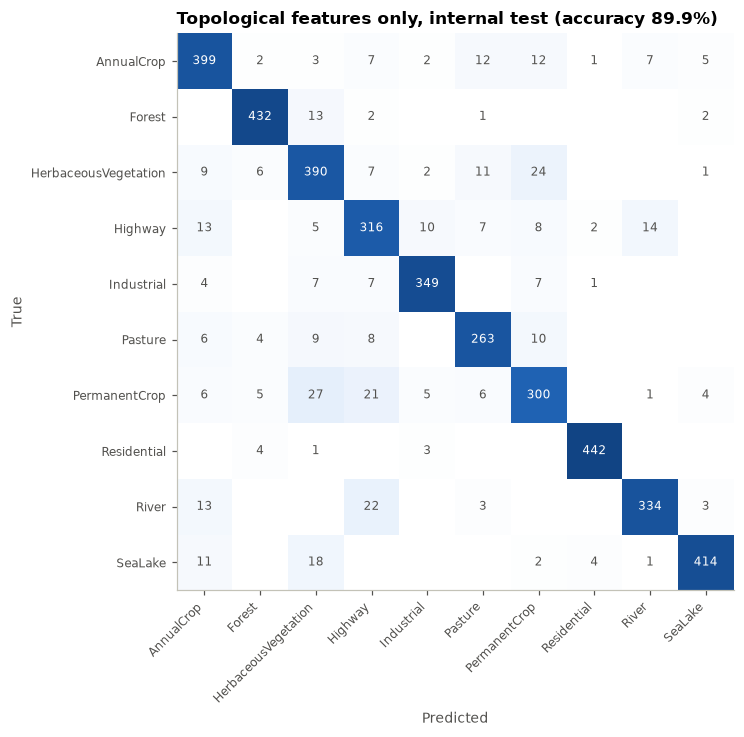

In [5]:
te_pred = models["topological"].predict(T_all[te])
plot_confusion_matrix(y_all[te], te_pred,
                      f"Topological features only, internal test (accuracy {acc.loc['topological', 'internal test']:.1%})")

## 5 · How different are the features on Kaggle images?

A classifier tries to tell EuroSAT training images from Kaggle images, with 5-fold cross-validation.
Only land images on both sides, so the higher Kaggle water share doesn't count as a difference.
AUC 0.5 = the feature set looks the same in both domains, 1.0 = perfectly separable.

In [6]:
eu_land = np.flatnonzero(tr & land_mask(X_all))
kg_land = np.flatnonzero(land_mask(X_kg))
eu_land = rng.choice(eu_land, len(kg_land), replace=False)
domain = np.r_[np.zeros(len(eu_land)), np.ones(len(kg_land))]

def domain_auc(F_eu, F_kg):
    F = np.vstack([F_eu[eu_land], F_kg[kg_land]])
    clf = HistGradientBoostingClassifier(max_iter=200, random_state=SEED)
    p = cross_val_predict(clf, F, domain, cv=5, method="predict_proba")[:, 1]
    return roc_auc_score(domain, p)

auc = pd.Series({
    "spectral, EuroSAT raw": domain_auc(spectral_features(X_all), S_kg),
    "spectral, EuroSAT hist_split": domain_auc(S_all, S_kg),
    "topological": domain_auc(T_all, T_kg),
}, name="EuroSAT vs Kaggle AUC")
auc.round(3).to_frame()

,EuroSAT vs Kaggle AUC
"spectral, EuroSAT raw",1.000
"spectral, EuroSAT hist_split",0.999
topological,0.914


Which topological features differ most between the domains? Standardised mean difference
(Kaggle land minus EuroSAT land, in EuroSAT standard deviations).

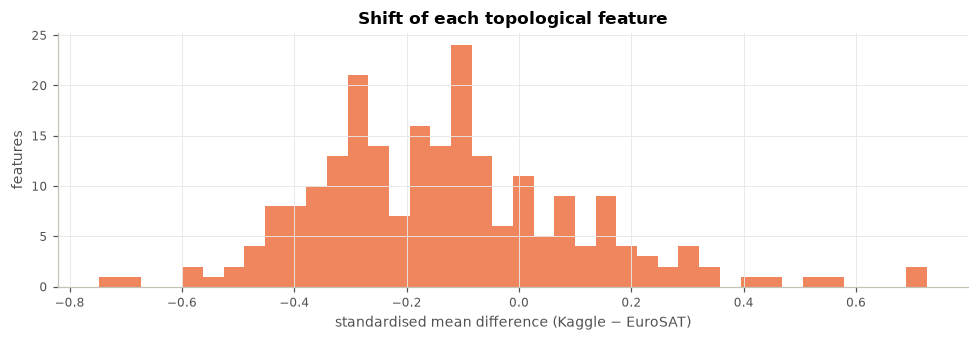

,difference (SD)
ndvi_super_H1_mean_mid,-0.75
ndvi_sub_H0_mean_mid,0.73
ndvi_super_H1_mean_birth,-0.69
ndvi_sub_H0_mean_birth,0.69
vis_sub_H1_mean_mid,-0.60
vis_sub_H1_mean_birth,-0.58
vis_super_H0_mean_mid,0.54
vis_super_H0_mean_birth,0.53
ndvi_super_H1_betti@0.95,-0.53
ndvi_sub_H0_entropy,-0.52


In [7]:
mu_eu, sd_eu = T_all[eu_land].mean(0), T_all[eu_land].std(0) + 1e-6
smd = pd.Series((T_kg[kg_land].mean(0) - mu_eu) / sd_eu, index=names)
smd = smd[smd.abs().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(smd.values, bins=40, color=TEST_COLOR, alpha=0.8)
ax.set(xlabel="standardised mean difference (Kaggle − EuroSAT)", ylabel="features",
       title="Shift of each topological feature")
plt.tight_layout()
plt.show()
smd.head(10).round(2).to_frame("difference (SD)")

## 6 · Predictions on Kaggle images vs E06c

E06c + AdaBN is about 71.5% correct overall and much more often right where it is confident, so agreement
with E06c on its **confident** images (≥ 0.8) is a rough, label-free stand-in for accuracy. On its
**uncertain** images (< 0.6), we check how often the topological model picks E06c's first or second choice.

In [8]:
device = get_device()
e10_model, e10_norm, _ = load_run(find_run(REFERENCE_RUN), device)
e10_prob = predict_views(e10_model, to_device_images(X_kg, device), e10_norm).mean(0)
del e10_model
e10_order = np.argsort(-e10_prob, axis=1)
e10_pred, e10_second, e10_conf = e10_order[:, 0], e10_order[:, 1], e10_prob.max(1)
confident, uncertain = e10_conf >= 0.8, e10_conf < 0.6

rows = {}
kg_pred = {}
for k, m in models.items():
    p = m.predict(feats_kg[k])
    kg_pred[k] = p
    rows[k] = {
        "agree, all images": (p == e10_pred).mean(),
        "agree, E06c confident (≥0.8)": (p == e10_pred)[confident].mean(),
        "agree, E06c uncertain (<0.6)": (p == e10_pred)[uncertain].mean(),
        "E06c's 1st or 2nd, uncertain": ((p == e10_pred) | (p == e10_second))[uncertain].mean(),
    }
print(f"E06c confident: {confident.sum():,} images, uncertain: {uncertain.sum():,}")
(pd.DataFrame(rows).T * 100).round(1)

E06c confident: 3,344 images, uncertain: 451


,"agree, all images","agree, E06c confident (≥0.8)","agree, E06c uncertain (<0.6)","E06c's 1st or 2nd, uncertain"
topological,43.8,47.2,25.9,53.2
spectral,51.3,58.9,18.8,37.0
topological + spectral,63.2,71.9,25.5,46.8


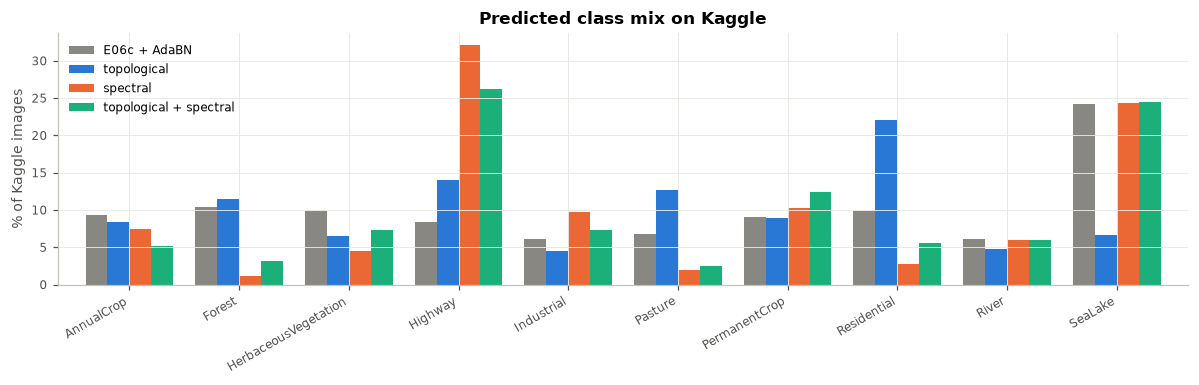

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
E06c + AdaBN,9.4,10.3,9.9,8.4,6.2,6.7,9.0,9.8,6.1,24.2
topological,8.4,11.5,6.5,14.1,4.6,12.7,8.9,22.0,4.7,6.6
spectral,7.5,1.1,4.5,32.1,9.8,1.9,10.2,2.7,5.9,24.3
topological + spectral,5.2,3.2,7.3,26.2,7.4,2.5,12.4,5.5,6.0,24.4


In [9]:
mix = pd.DataFrame({"E06c + AdaBN": np.bincount(e10_pred, minlength=10),
                    **{k: np.bincount(p, minlength=10) for k, p in kg_pred.items()}},
                   index=CLASSES) / len(X_kg) * 100
ax = mix.plot.bar(figsize=(11, 3.6), width=0.8, color=[MUTED, TRAIN_COLOR, TEST_COLOR, "#1baf7a"])
ax.set(ylabel="% of Kaggle images", title="Predicted class mix on Kaggle")
plt.xticks(rotation=30, ha="right", fontsize=8)
plt.tight_layout()
plt.show()
mix.round(1).T

Per class, on E06c's confident images: how often does the topological model agree?
This shows which classes topology describes in a domain-robust way.

In [10]:
per_class = pd.DataFrame({
    k: pd.Series(p[confident] == e10_pred[confident]).groupby(e10_pred[confident]).mean()
    for k, p in kg_pred.items()})
per_class.index = [CLASSES[i] for i in per_class.index]
per_class["EuroSAT internal test (topological)"] = pd.Series(
    te_pred == y_all[te]).groupby(y_all[te]).mean().values
(per_class * 100).round(1)

,topological,spectral,topological + spectral,EuroSAT internal test (topological)
AnnualCrop,54.3,38.5,46.8,88.7
Forest,72.1,13.8,36.6,96.0
HerbaceousVegetation,26.2,30.5,46.1,86.7
Highway,70.3,47.0,82.4,84.3
Industrial,49.0,87.9,83.8,93.1
Pasture,64.7,24.7,35.8,87.7
PermanentCrop,41.2,55.6,64.2,80.0
Residential,64.2,22.5,67.1,98.2
River,66.0,78.1,84.2,89.1
SeaLake,25.0,99.6,99.9,92.0


## 7 · Conclusion

| Feature set | EuroSAT internal test | EuroSAT vs Kaggle AUC | Agreement with E06c, E06c confident |
|---|---|---|---|
| spectral statistics | 91.5% | 0.999 | 58.9% |
| **topological** | 89.9% | **0.914** | 47.2% |
| topological + spectral | 96.1% | – | 71.9% |

- **Topology alone classifies EuroSAT reasonably** (89.9%, close to the 92.4% reported by Sharma 2025), far below the CNN (99%).
- **Topological features are clearly more alike across the domains** (AUC 0.91 vs 0.999 for spectral statistics, even after
  `hist_split`), so the idea that geometry transfers better is confirmed. They are not invariant, though: the largest
  shifts are in the NDVI and visible-brightness diagrams (when regions appear), because NDVI and the visible mean mix bands
  that changed differently between Level-1C and Level-2A, and because Kaggle scenes are more often mixed.
- **On Kaggle, the topological model is still weak:** it agrees with E06c on only 47% of the images E06c is confident about.
  It describes Forest, Highway, Pasture, Residential and River fairly well (64–72%), but fails on **SeaLake** (25%):
  rank normalisation turns a uniform water surface into noise, so the "dark and flat" information is lost.
  On E06c's uncertain images, it picks E06c's first or second choice 53% of the time, so it does carry some signal there.
- **Combined with spectral features**, the boosting model improves on both, but stays well below the CNN on Kaggle
  (about 72% agreement on E06c's confident images, i.e. probably far below 71.5% accuracy overall).

**Verdict.** Persistent homology confirms that shape transfers better than band values, but as a separate
model it is too weak to help an ensemble with E06c: averaging with a model that is right much less often would mostly add
errors. More promising ways to use the finding: make the CNN rely more on shape (per-image normalised input,
stronger photometric augmentation), or feed a few topological features (NIR/edges, not NDVI) into the CNN's head as
in Sharma 2025, which needs a training run.